In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")

# Kaggle API authentication
os.environ["KAGGLE_API_TOKEN"] = "KGAT_13f43e065aa3cb99805730baca5cb57c"

import kagglehub
import xgboost as xgb

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

from statsmodels.tsa.arima.model import ARIMA
from prophet import Prophet

print("Libraries loaded successfully.")
print("Kaggle API token configured successfully.")

Libraries loaded successfully.
Kaggle API token configured successfully.


In [ ]:
# Download Rossmann Store Sales dataset
path = kagglehub.competition_download(
    "rossmann-store-sales"
)

print("Dataset downloaded to:")
print(path)

# File paths
train_file = os.path.join(
    path,
    "train.csv"
)

store_file = os.path.join(
    path,
    "store.csv"
)

# Load datasets
df_sales = pd.read_csv(
    train_file,
    parse_dates=["Date"]
)

df_store = pd.read_csv(
    store_file
)

# Convert StateHoliday to string
df_sales["StateHoliday"] = (
    df_sales["StateHoliday"].astype(str)
)

print("\nSales shape:", df_sales.shape)
print("Store shape:", df_store.shape)

print("\nSales data:")
display(df_sales.head())

print("\nStore data:")
display(df_store.head())

100%|██████████| 6.99M/6.99M [00:00<00:00, 69.0MB/s]

Extracting files...


Dataset downloaded to:
/root/.cache/kagglehub/competitions/rossmann-store-sales

Sales shape: (1017209, 9)
Store shape: (1115, 10)

Sales data:


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1



Store data:


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [ ]:
def evaluate_forecast(y_true, y_pred):
    """
    Calculate multiple forecasting metrics.

    WMAPE is preferred over ordinary MAPE because
    the Rossmann dataset contains zero-sales observations.
    """

    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    # Prevent negative predictions
    y_pred = np.maximum(y_pred, 0)

    mae = mean_absolute_error(y_true, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    wmape = (
        np.sum(np.abs(y_true - y_pred))
        / np.sum(np.abs(y_true))
    ) * 100

    forecast_accuracy = 100 - wmape

    return {
        "MAE": mae,
        "RMSE": rmse,
        "WMAPE": wmape,
        "Forecast Accuracy": forecast_accuracy
    }


def print_metrics(name, metrics):
    print(f"\n===== {name} =====")
    print(f"MAE               : {metrics['MAE']:,.2f}")
    print(f"RMSE              : {metrics['RMSE']:,.2f}")
    print(f"WMAPE             : {metrics['WMAPE']:.2f}%")
    print(f"Forecast Accuracy : {metrics['Forecast Accuracy']:.2f}%")

Store 1 shape: (942, 8)


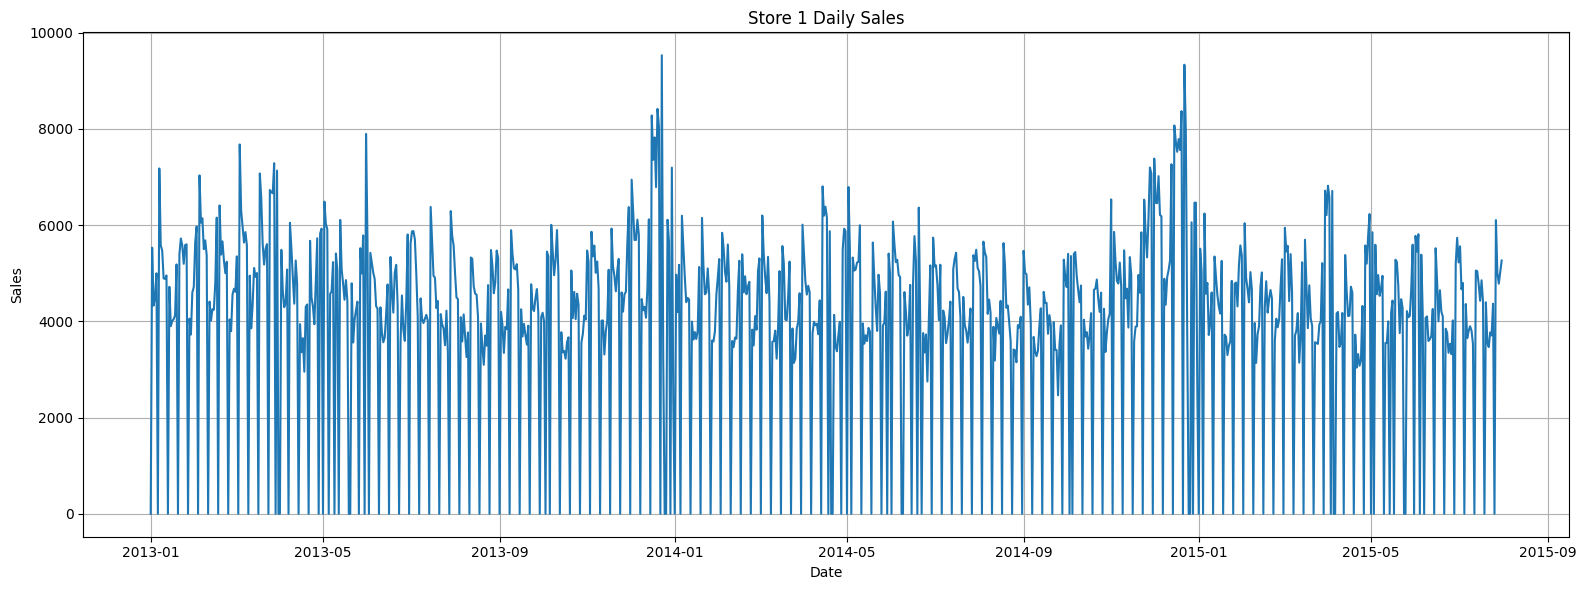

In [ ]:
store_id = 1
test_size = 60

store_1 = df_sales[
    df_sales["Store"] == store_id
].copy()

store_1 = store_1.sort_values("Date")

store_1.set_index(
    "Date",
    inplace=True
)

print("Store 1 shape:", store_1.shape)

plt.figure(figsize=(16, 6))

plt.plot(
    store_1.index,
    store_1["Sales"]
)

plt.title("Store 1 Daily Sales")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
def create_time_features(df):
    """
    Create calendar features without using future sales.
    """

    df = df.copy()

    df["Year"] = df.index.year
    df["Month"] = df.index.month
    df["DayOfMonth"] = df.index.day

    df["DayOfWeek"] = df.index.dayofweek
    df["WeekOfYear"] = df.index.isocalendar().week.astype(int)

    df["IsMonthStart"] = (
        df.index.is_month_start.astype(int)
    )

    df["IsMonthEnd"] = (
        df.index.is_month_end.astype(int)
    )

    return df

In [ ]:
def create_training_features(df):
    """
    Create leakage-free one-step-ahead training features.
    """

    data = df.copy()

    # Convert StateHoliday to numeric
    # 0 = no holiday
    # 1 = public holiday
    # 2 = Easter
    # 3 = Christmas
    data["StateHoliday"] = (
        data["StateHoliday"]
        .map({
            "0": 0,
            "a": 1,
            "b": 2,
            "c": 3
        })
        .fillna(0)
        .astype(int)
    )

    # Time features
    data = create_time_features(data)

    # Lag features
    data["Lag_1"] = data["Sales"].shift(1)
    data["Lag_7"] = data["Sales"].shift(7)
    data["Lag_14"] = data["Sales"].shift(14)
    data["Lag_28"] = data["Sales"].shift(28)

    # Shift first -> prevents data leakage
    shifted_sales = data["Sales"].shift(1)

    # Rolling features
    data["Rolling_Mean_7"] = (
        shifted_sales.rolling(7).mean()
    )

    data["Rolling_Mean_14"] = (
        shifted_sales.rolling(14).mean()
    )

    data["Rolling_Mean_28"] = (
        shifted_sales.rolling(28).mean()
    )

    data["Rolling_Std_7"] = (
        shifted_sales.rolling(7).std()
    )

    data["Rolling_Std_14"] = (
        shifted_sales.rolling(14).std()
    )

    data["Rolling_Std_28"] = (
        shifted_sales.rolling(28).std()
    )

    # Promotion × previous sales
    data["Promo_Lag1"] = (
        data["Promo"] * data["Lag_1"]
    )

    # Remove rows where lag/rolling features don't exist
    data = data.dropna()

    return data

In [ ]:
store_train_features = create_training_features(
    store_1
)

print(
    "Training feature shape:",
    store_train_features.shape
)

display(
    store_train_features.head()
)
print(store_train_features.dtypes)

Training feature shape: (914, 25)


,Store,DayOfWeek,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,Year,Month,...,Lag_7,Lag_14,Lag_28,Rolling_Mean_7,Rolling_Mean_14,Rolling_Mean_28,Rolling_Std_7,Rolling_Std_14,Rolling_Std_28,Promo_Lag1
Date,,,,,,,,,,,,,,,,,,,,,
2013-01-29,1,1,3725,522,1,0,0,0,2013,1,...,5720.0,3900.0,0.0,4533.142857,4170.500000,4121.285714,2080.017823,1899.595898,2075.631146,0.0
2013-01-30,1,2,4601,560,1,0,0,0,2013,1,...,5578.0,4008.0,5530.0,4248.142857,4158.000000,4254.321429,2026.274696,1902.086951,1914.845455,0.0
2013-01-31,1,3,4709,571,1,0,0,0,2013,1,...,5195.0,4044.0,4327.0,4108.571429,4200.357143,4221.142857,1951.681400,1905.090008,1899.913267,0.0
2013-02-01,1,4,5633,658,1,0,0,0,2013,2,...,5586.0,4127.0,4486.0,4039.142857,4247.857143,4234.785714,1914.889329,1909.177546,1902.071860,0.0
2013-02-02,1,5,5970,701,1,0,0,0,2013,2,...,5598.0,5182.0,4997.0,4045.857143,4355.428571,4275.750000,1921.288841,1943.954681,1919.949818,0.0


Store                int64
DayOfWeek            int32
Sales                int64
Customers            int64
Open                 int64
Promo                int64
StateHoliday         int64
SchoolHoliday        int64
Year                 int32
Month                int32
DayOfMonth           int32
WeekOfYear           int64
IsMonthStart         int64
IsMonthEnd           int64
Lag_1              float64
Lag_7              float64
Lag_14             float64
Lag_28             float64
Rolling_Mean_7     float64
Rolling_Mean_14    float64
Rolling_Mean_28    float64
Rolling_Std_7      float64
Rolling_Std_14     float64
Rolling_Std_28     float64
Promo_Lag1         float64
dtype: object


In [ ]:
target = "Sales"

exclude_columns = [
    "Sales",
    "Customers",
    "StateHoliday"
]

feature_columns = [
    col
    for col in store_train_features.columns
    if col not in exclude_columns
]

print("Number of features:", len(feature_columns))
print("\nFeatures:")
print(feature_columns)

Number of features: 22

Features:
['Store', 'DayOfWeek', 'Open', 'Promo', 'SchoolHoliday', 'Year', 'Month', 'DayOfMonth', 'WeekOfYear', 'IsMonthStart', 'IsMonthEnd', 'Lag_1', 'Lag_7', 'Lag_14', 'Lag_28', 'Rolling_Mean_7', 'Rolling_Mean_14', 'Rolling_Mean_28', 'Rolling_Std_7', 'Rolling_Std_14', 'Rolling_Std_28', 'Promo_Lag1']


In [ ]:
train_data = store_train_features.iloc[:-test_size]
test_data = store_train_features.iloc[-test_size:]

X_train = train_data[feature_columns]
y_train = train_data["Sales"]

X_test = test_data[feature_columns]
y_test = test_data["Sales"]

print("Training period:")
print(train_data.index.min(), "to", train_data.index.max())

print("\nTesting period:")
print(test_data.index.min(), "to", test_data.index.max())

print("\nTraining rows:", len(X_train))
print("Testing rows :", len(X_test))

Training period:
2013-01-29 00:00:00 to 2015-06-01 00:00:00

Testing period:
2015-06-02 00:00:00 to 2015-07-31 00:00:00

Training rows: 854
Testing rows : 60


In [ ]:
xgb_model = xgb.XGBRegressor(
    n_estimators=800,
    learning_rate=0.03,
    max_depth=6,

    subsample=0.85,
    colsample_bytree=0.85,

    min_child_weight=5,

    reg_alpha=0.1,
    reg_lambda=1.0,

    objective="reg:squarederror",

    random_state=42,
    n_jobs=-1
)
print("Training XGBoost...")

xgb_model.fit(
    X_train,
    y_train
)

print("XGBoost training complete.")

Training XGBoost...
XGBoost training complete.


In [ ]:
def recursive_xgb_forecast(
    model,
    historical_df,
    future_df,
    feature_columns
):
    """
    Recursive multi-step forecasting.

    Actual future Sales values are never used
    to generate future lag features.
    """

    history = historical_df.copy()

    predictions = []

    for date in future_df.index:

        row = future_df.loc[date].copy()

        # Combine historical actual/predicted sales
        sales_history = history["Sales"]

        row["Year"] = date.year
        row["Month"] = date.month
        row["DayOfMonth"] = date.day
        row["DayOfWeek"] = date.dayofweek
        row["WeekOfYear"] = int(date.isocalendar().week)
        row["IsMonthStart"] = int(date.is_month_start)
        row["IsMonthEnd"] = int(date.is_month_end)

        # Lags
        row["Lag_1"] = sales_history.iloc[-1]

        row["Lag_7"] = (
            sales_history.iloc[-7]
            if len(sales_history) >= 7
            else sales_history.mean()
        )

        row["Lag_14"] = (
            sales_history.iloc[-14]
            if len(sales_history) >= 14
            else sales_history.mean()
        )

        row["Lag_28"] = (
            sales_history.iloc[-28]
            if len(sales_history) >= 28
            else sales_history.mean()
        )

        # Rolling statistics
        row["Rolling_Mean_7"] = (
            sales_history
            .tail(7)
            .mean()
        )

        row["Rolling_Mean_14"] = (
            sales_history
            .tail(14)
            .mean()
        )

        row["Rolling_Mean_28"] = (
            sales_history
            .tail(28)
            .mean()
        )

        row["Rolling_Std_7"] = (
            sales_history
            .tail(7)
            .std()
        )

        row["Rolling_Std_14"] = (
            sales_history
            .tail(14)
            .std()
        )

        row["Rolling_Std_28"] = (
            sales_history
            .tail(28)
            .std()
        )

        row["Promo_Lag1"] = (
            row["Promo"] * row["Lag_1"]
        )

        row_df = pd.DataFrame(
            [row],
            index=[date]
        )

        X_future = row_df[
            feature_columns
        ]

        prediction = model.predict(
            X_future
        )[0]

        prediction = max(
            prediction,
            0
        )

        predictions.append(prediction)

        # Add prediction to history
        new_row = row.copy()
        new_row["Sales"] = prediction

        history.loc[date] = new_row

    return np.array(predictions)

In [ ]:
future_exogenous = store_1.iloc[-test_size:].copy()

# Only use data BEFORE the test period as historical information
historical_store = store_1.iloc[:-test_size].copy()

xgb_predictions = recursive_xgb_forecast(
    xgb_model,
    historical_store,
    future_exogenous,
    feature_columns
)

xgb_metrics = evaluate_forecast(
    y_test,
    xgb_predictions
)

print_metrics(
    "Store 1 - XGBoost",
    xgb_metrics
)


===== Store 1 - XGBoost =====
MAE               : 260.11
RMSE              : 360.35
WMAPE             : 6.92%
Forecast Accuracy : 93.08%


In [ ]:
# Train XGBoost on log-transformed sales

log_xgb_model = xgb.XGBRegressor(
    n_estimators=800,
    learning_rate=0.03,
    max_depth=6,
    subsample=0.85,
    colsample_bytree=0.85,
    min_child_weight=5,
    reg_alpha=0.1,
    reg_lambda=1.0,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

print("Training Log-XGBoost...")

log_xgb_model.fit(
    X_train,
    np.log1p(y_train)
)

print("Log-XGBoost training complete.")

Training Log-XGBoost...
Log-XGBoost training complete.


In [ ]:
def recursive_log_xgb_forecast(
    model,
    historical_df,
    future_df,
    feature_columns
):

    history = historical_df.copy()

    predictions = []

    for date in future_df.index:

        row = future_df.loc[date].copy()

        sales_history = history["Sales"]

        # Calendar features
        row["Year"] = date.year
        row["Month"] = date.month
        row["DayOfMonth"] = date.day
        row["DayOfWeek"] = date.dayofweek
        row["WeekOfYear"] = int(date.isocalendar().week)
        row["IsMonthStart"] = int(date.is_month_start)
        row["IsMonthEnd"] = int(date.is_month_end)

        # Lag features
        row["Lag_1"] = sales_history.iloc[-1]
        row["Lag_7"] = sales_history.iloc[-7]
        row["Lag_14"] = sales_history.iloc[-14]
        row["Lag_28"] = sales_history.iloc[-28]

        # Rolling features
        row["Rolling_Mean_7"] = (
            sales_history.tail(7).mean()
        )

        row["Rolling_Mean_14"] = (
            sales_history.tail(14).mean()
        )

        row["Rolling_Mean_28"] = (
            sales_history.tail(28).mean()
        )

        row["Rolling_Std_7"] = (
            sales_history.tail(7).std()
        )

        row["Rolling_Std_14"] = (
            sales_history.tail(14).std()
        )

        row["Rolling_Std_28"] = (
            sales_history.tail(28).std()
        )

        # Promotion interaction
        row["Promo_Lag1"] = (
            row["Promo"] * row["Lag_1"]
        )

        row_df = pd.DataFrame(
            [row],
            index=[date]
        )

        X_future = row_df[
            feature_columns
        ]

        # Predict log sales
        prediction_log = model.predict(
            X_future
        )[0]

        # Convert back to original sales scale
        prediction = np.expm1(
            prediction_log
        )

        prediction = max(
            prediction,
            0
        )

        predictions.append(prediction)

        # Add prediction to history for next step
        new_row = row.copy()
        new_row["Sales"] = prediction

        history.loc[date] = new_row

    return np.array(predictions)

In [ ]:
log_xgb_predictions = recursive_log_xgb_forecast(
    log_xgb_model,
    historical_store,
    future_exogenous,
    feature_columns
)

log_xgb_metrics = evaluate_forecast(
    y_test,
    log_xgb_predictions
)

print_metrics(
    "Store 1 - Log XGBoost",
    log_xgb_metrics
)


===== Store 1 - Log XGBoost =====
MAE               : 271.32
RMSE              : 386.14
WMAPE             : 7.22%
Forecast Accuracy : 92.78%


In [ ]:
prophet_data = store_1.reset_index()

prophet_data = prophet_data.rename(
    columns={
        "Date": "ds",
        "Sales": "y"
    }
)

prophet_regressors = [
    "Open",
    "Promo"
]

prophet_train = (
    prophet_data.iloc[:-test_size]
)

prophet_test = (
    prophet_data.iloc[-test_size:]
)

prophet_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False
)

for col in prophet_regressors:
    prophet_model.add_regressor(col)

print("Training Prophet...")

prophet_model.fit(
    prophet_train[
        ["ds", "y"] + prophet_regressors
    ]
)

prophet_future = prophet_test[
    ["ds"] + prophet_regressors
]

prophet_output = prophet_model.predict(
    prophet_future
)

prophet_predictions = np.maximum(
    prophet_output["yhat"].values,
    0
)

prophet_metrics = evaluate_forecast(
    prophet_test["y"],
    prophet_predictions
)

print_metrics(
    "Store 1 - Prophet",
    prophet_metrics
)

Training Prophet...

===== Store 1 - Prophet =====
MAE               : 295.14
RMSE              : 406.19
WMAPE             : 7.85%
Forecast Accuracy : 92.15%


In [ ]:
store_results = pd.DataFrame({
    "Model": [
        "XGBoost",
        "Log-XGBoost",
        "Prophet"
    ],
    "MAE": [
        xgb_metrics["MAE"],
        log_xgb_metrics["MAE"],
        prophet_metrics["MAE"]
    ],
    "RMSE": [
        xgb_metrics["RMSE"],
        log_xgb_metrics["RMSE"],
        prophet_metrics["RMSE"]
    ],
    "WMAPE (%)": [
        xgb_metrics["WMAPE"],
        log_xgb_metrics["WMAPE"],
        prophet_metrics["WMAPE"]
    ],
    "Forecast Accuracy (%)": [
        xgb_metrics["Forecast Accuracy"],
        log_xgb_metrics["Forecast Accuracy"],
        prophet_metrics["Forecast Accuracy"]
    ]
})

store_results = store_results.sort_values("WMAPE (%)")
display(store_results.round(2))

,Model,MAE,RMSE,WMAPE (%),Forecast Accuracy (%)
0,XGBoost,260.11,360.35,6.92,93.08
1,Log-XGBoost,271.32,386.14,7.22,92.78
2,Prophet,295.14,406.19,7.85,92.15


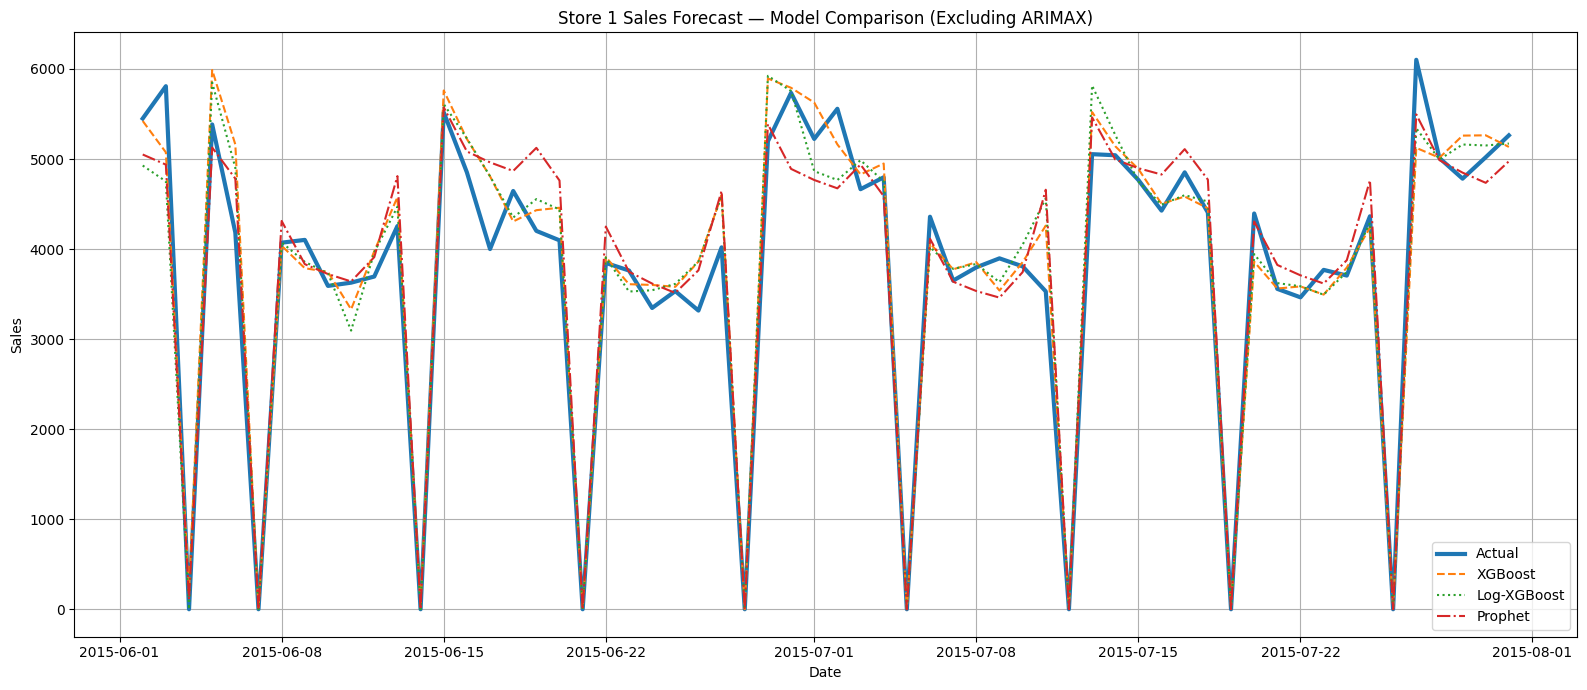

In [ ]:
plt.figure(figsize=(16, 7))
plt.plot(y_test.index, y_test.values, label="Actual", linewidth=3)
plt.plot(y_test.index, xgb_predictions, label="XGBoost", linestyle="--")
plt.plot(y_test.index, log_xgb_predictions, label="Log-XGBoost", linestyle=":")
plt.plot(y_test.index, prophet_predictions, label="Prophet", linestyle="-.")

plt.title("Store 1 Sales Forecast — Model Comparison (Excluding ARIMAX)")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# Aggregate sales across all stores by date

df_macro = df_sales.groupby("Date").agg(
    Total_Sales=("Sales", "sum"),
    Stores_Open=("Open", "sum"),
    Stores_Promo=("Promo", "sum")
)

# Count stores affected by state holidays
holiday_counts = (
    df_sales[df_sales["StateHoliday"] != "0"]
    .groupby("Date")
    .size()
)

df_macro["Stores_on_Holiday"] = (
    holiday_counts
    .reindex(df_macro.index)
    .fillna(0)
)

df_macro = df_macro.sort_index()

print("National dataset shape:", df_macro.shape)
display(df_macro.head())

National dataset shape: (942, 4)


,Total_Sales,Stores_Open,Stores_Promo,Stores_on_Holiday
Date,,,,
2013-01-01,97235,17,0,1114.0
2013-01-02,6949829,1111,0,0.0
2013-01-03,6347820,1109,0,0.0
2013-01-04,6638954,1108,0,0.0
2013-01-05,5951593,1107,0,0.0


In [ ]:
# Calendar features

df_macro["Year"] = df_macro.index.year
df_macro["Month"] = df_macro.index.month
df_macro["DayOfMonth"] = df_macro.index.day
df_macro["DayOfWeek"] = df_macro.index.dayofweek

df_macro["WeekOfYear"] = (
    df_macro.index
    .isocalendar()
    .week
    .astype(int)
)

df_macro["IsMonthStart"] = (
    df_macro.index.is_month_start.astype(int)
)

df_macro["IsMonthEnd"] = (
    df_macro.index.is_month_end.astype(int)
)

# Business ratios
df_macro["Open_Rate"] = (
    df_macro["Stores_Open"] / 1115
)

df_macro["Promo_Rate"] = (
    df_macro["Stores_Promo"]
    / df_macro["Stores_Open"].replace(0, np.nan)
)

df_macro["Promo_Rate"] = (
    df_macro["Promo_Rate"].fillna(0)
)

display(df_macro.head())

,Total_Sales,Stores_Open,Stores_Promo,Stores_on_Holiday,Year,Month,DayOfMonth,DayOfWeek,WeekOfYear,IsMonthStart,IsMonthEnd,Open_Rate,Promo_Rate
Date,,,,,,,,,,,,,
2013-01-01,97235,17,0,1114.0,2013,1,1,1,1,1,0,0.015247,0.0
2013-01-02,6949829,1111,0,0.0,2013,1,2,2,1,0,0,0.996413,0.0
2013-01-03,6347820,1109,0,0.0,2013,1,3,3,1,0,0,0.994619,0.0
2013-01-04,6638954,1108,0,0.0,2013,1,4,4,1,0,0,0.993722,0.0
2013-01-05,5951593,1107,0,0.0,2013,1,5,5,1,0,0,0.992825,0.0


In [ ]:
macro_features = df_macro.copy()

# Lag features
macro_features["Lag_1"] = (
    macro_features["Total_Sales"].shift(1)
)

macro_features["Lag_7"] = (
    macro_features["Total_Sales"].shift(7)
)

macro_features["Lag_14"] = (
    macro_features["Total_Sales"].shift(14)
)

macro_features["Lag_28"] = (
    macro_features["Total_Sales"].shift(28)
)

# Previous sales only
shifted_sales = (
    macro_features["Total_Sales"].shift(1)
)

# Rolling averages
macro_features["Rolling_Mean_7"] = (
    shifted_sales.rolling(7).mean()
)

macro_features["Rolling_Mean_14"] = (
    shifted_sales.rolling(14).mean()
)

macro_features["Rolling_Mean_28"] = (
    shifted_sales.rolling(28).mean()
)

# Rolling volatility
macro_features["Rolling_Std_7"] = (
    shifted_sales.rolling(7).std()
)

macro_features["Rolling_Std_14"] = (
    shifted_sales.rolling(14).std()
)

macro_features["Rolling_Std_28"] = (
    shifted_sales.rolling(28).std()
)

macro_features = macro_features.dropna()

print(
    "National feature dataset:",
    macro_features.shape
)

National feature dataset: (914, 23)


In [ ]:
macro_train = macro_features.iloc[:-test_size]
macro_test = macro_features.iloc[-test_size:]

macro_feature_columns = [
    col
    for col in macro_features.columns
    if col != "Total_Sales"
]

X_macro_train = macro_train[
    macro_feature_columns
]

y_macro_train = macro_train[
    "Total_Sales"
]

X_macro_test = macro_test[
    macro_feature_columns
]

y_macro_test = macro_test[
    "Total_Sales"
]

print(
    "Training observations:",
    len(X_macro_train)
)

print(
    "Testing observations:",
    len(X_macro_test)
)

print(
    "\nTest period:",
    macro_test.index.min(),
    "to",
    macro_test.index.max()
)

Training observations: 854
Testing observations: 60

Test period: 2015-06-02 00:00:00 to 2015-07-31 00:00:00


In [ ]:
macro_xgb_model = xgb.XGBRegressor(
    n_estimators=800,
    learning_rate=0.03,
    max_depth=6,

    subsample=0.85,
    colsample_bytree=0.85,

    min_child_weight=5,

    reg_alpha=0.1,
    reg_lambda=1.0,

    objective="reg:squarederror",

    random_state=42,
    n_jobs=-1
)

print("Training National XGBoost...")

macro_xgb_model.fit(
    X_macro_train,
    y_macro_train
)

print("Training complete.")

Training National XGBoost...
Training complete.


In [ ]:
def recursive_macro_xgb_forecast(
    model,
    historical_df,
    future_df,
    feature_columns
):

    history = historical_df.copy()

    predictions = []

    for date in future_df.index:

        row = future_df.loc[date].copy()

        sales_history = history["Total_Sales"]

        # Calendar features
        row["Year"] = date.year
        row["Month"] = date.month
        row["DayOfMonth"] = date.day
        row["DayOfWeek"] = date.dayofweek

        row["WeekOfYear"] = int(
            date.isocalendar().week
        )

        row["IsMonthStart"] = int(
            date.is_month_start
        )

        row["IsMonthEnd"] = int(
            date.is_month_end
        )

        # Lag features
        row["Lag_1"] = (
            sales_history.iloc[-1]
        )

        row["Lag_7"] = (
            sales_history.iloc[-7]
        )

        row["Lag_14"] = (
            sales_history.iloc[-14]
        )

        row["Lag_28"] = (
            sales_history.iloc[-28]
        )

        # Rolling means
        row["Rolling_Mean_7"] = (
            sales_history.tail(7).mean()
        )

        row["Rolling_Mean_14"] = (
            sales_history.tail(14).mean()
        )

        row["Rolling_Mean_28"] = (
            sales_history.tail(28).mean()
        )

        # Rolling standard deviation
        row["Rolling_Std_7"] = (
            sales_history.tail(7).std()
        )

        row["Rolling_Std_14"] = (
            sales_history.tail(14).std()
        )

        row["Rolling_Std_28"] = (
            sales_history.tail(28).std()
        )

        # Create one-row dataframe
        row_df = pd.DataFrame(
            [row],
            index=[date]
        )

        X_future = row_df[
            feature_columns
        ]

        prediction = model.predict(
            X_future
        )[0]

        prediction = max(
            prediction,
            0
        )

        predictions.append(prediction)

        # Add prediction to history
        new_row = row.copy()

        new_row["Total_Sales"] = (
            prediction
        )

        history.loc[date] = new_row

    return np.array(predictions)

In [ ]:
historical_macro = df_macro.iloc[:-test_size].copy()

future_macro = df_macro.iloc[-test_size:].copy()

macro_xgb_predictions = (
    recursive_macro_xgb_forecast(
        macro_xgb_model,
        historical_macro,
        future_macro,
        macro_feature_columns
    )
)

macro_xgb_metrics = evaluate_forecast(
    y_macro_test,
    macro_xgb_predictions
)

print_metrics(
    "National - XGBoost",
    macro_xgb_metrics
)


===== National - XGBoost =====
MAE               : 568,621.82
RMSE              : 852,119.77
WMAPE             : 8.36%
Forecast Accuracy : 91.64%


In [ ]:
macro_prophet_data = (
    df_macro
    .reset_index()
    .rename(
        columns={
            "Date": "ds",
            "Total_Sales": "y"
        }
    )
)

macro_regressors = [
    "Stores_Open",
    "Stores_Promo",
    "Stores_on_Holiday",
    "Open_Rate",
    "Promo_Rate"
]

macro_prophet_train = (
    macro_prophet_data.iloc[:-test_size]
)

macro_prophet_test = (
    macro_prophet_data.iloc[-test_size:]
)

macro_prophet_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False
)

for col in macro_regressors:
    macro_prophet_model.add_regressor(col)

print("Training National Prophet...")

macro_prophet_model.fit(
    macro_prophet_train[
        ["ds", "y"] + macro_regressors
    ]
)

macro_prophet_future = (
    macro_prophet_test[
        ["ds"] + macro_regressors
    ]
)

macro_prophet_output = (
    macro_prophet_model.predict(
        macro_prophet_future
    )
)

macro_prophet_predictions = np.maximum(
    macro_prophet_output["yhat"].values,
    0
)

macro_prophet_metrics = evaluate_forecast(
    macro_prophet_test["y"],
    macro_prophet_predictions
)

print_metrics(
    "National - Prophet",
    macro_prophet_metrics
)

Training National Prophet...

===== National - Prophet =====
MAE               : 460,809.07
RMSE              : 625,853.03
WMAPE             : 6.78%
Forecast Accuracy : 93.22%


In [ ]:
national_results = pd.DataFrame({
    "Model": [
        "XGBoost",
        "Prophet"
    ],
    "MAE": [
        macro_xgb_metrics["MAE"],
        macro_prophet_metrics["MAE"]
    ],
    "RMSE": [
        macro_xgb_metrics["RMSE"],
        macro_prophet_metrics["RMSE"]
    ],
    "WMAPE (%)": [
        macro_xgb_metrics["WMAPE"],
        macro_prophet_metrics["WMAPE"]
    ],
    "Forecast Accuracy (%)": [
        macro_xgb_metrics["Forecast Accuracy"],
        macro_prophet_metrics["Forecast Accuracy"]
    ]
})

national_results = national_results.sort_values("WMAPE (%)").reset_index(drop=True)
display(national_results.round(2))

,Model,MAE,RMSE,WMAPE (%),Forecast Accuracy (%)
0,Prophet,460809.07,625853.03,6.78,93.22
1,XGBoost,568621.82,852119.77,8.36,91.64


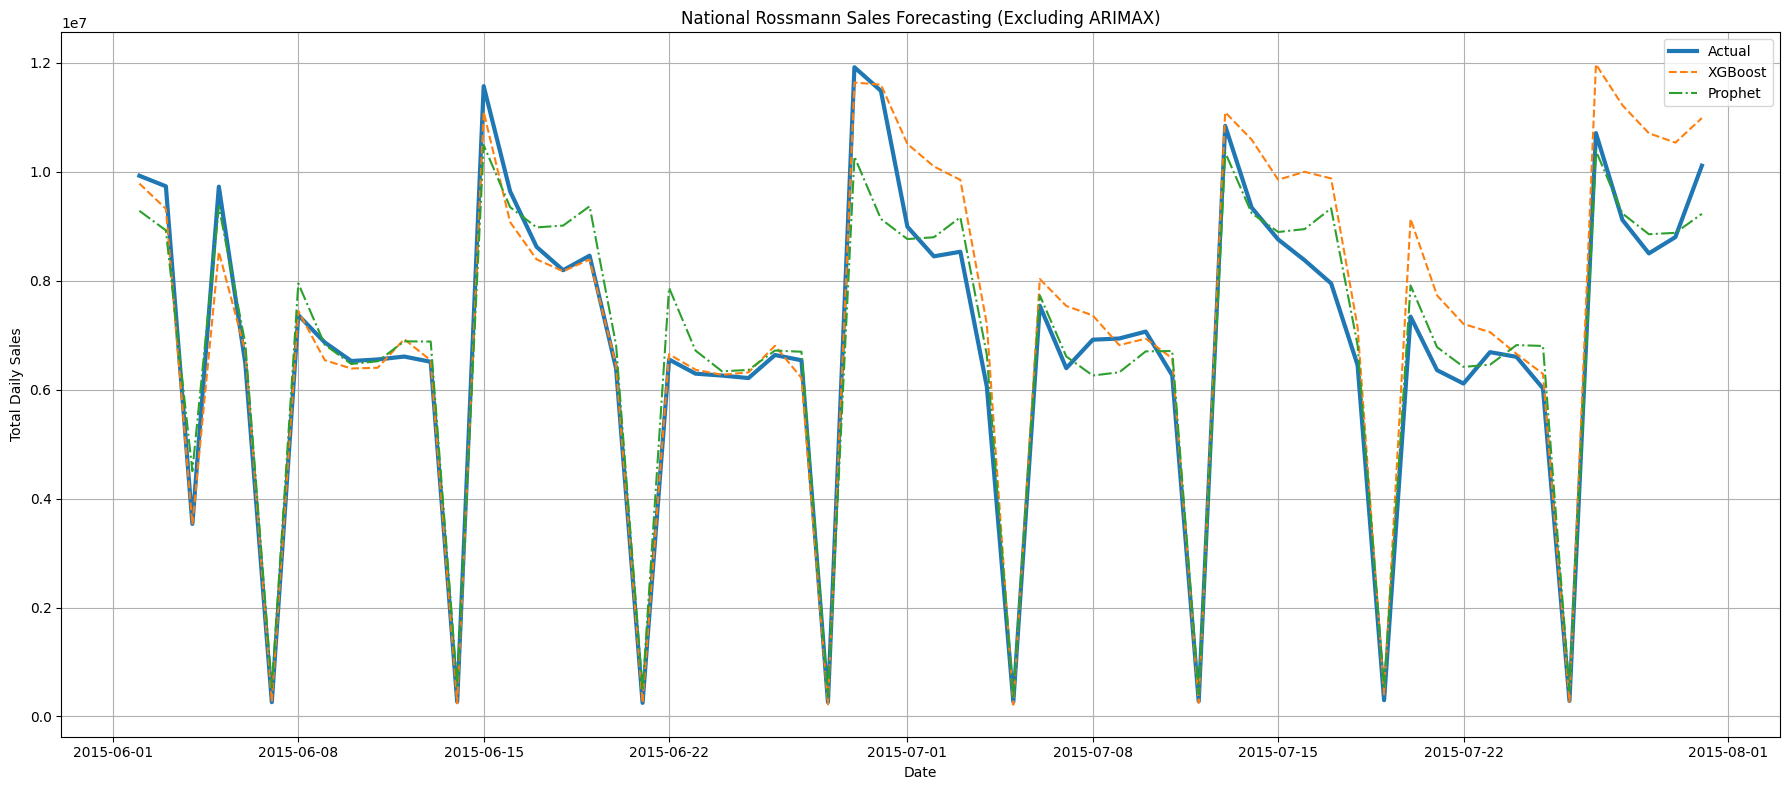

In [ ]:
plt.figure(figsize=(18, 8))
plt.plot(y_macro_test.index, y_macro_test.values, label="Actual", linewidth=3)
plt.plot(y_macro_test.index, macro_xgb_predictions, label="XGBoost", linestyle="--")
plt.plot(y_macro_test.index, macro_prophet_predictions, label="Prophet", linestyle="-.")

plt.title("National Rossmann Sales Forecasting (Excluding ARIMAX)")
plt.xlabel("Date")
plt.ylabel("Total Daily Sales")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
print("=" * 70)
print("FINAL PROJECT RESULTS")
print("=" * 70)

print("\nSTORE-LEVEL RESULTS")
display(
    store_results.round(2)
)

print("\nNATIONAL-LEVEL RESULTS")
display(
    national_results.round(2)
)

best_store = store_results.iloc[0]
best_national = national_results.iloc[0]

print("\n" + "=" * 70)

print(
    f"Best Store-Level Model: {best_store['Model']}"
)

print(
    f"Store-Level Accuracy: "
    f"{best_store['Forecast Accuracy (%)']:.2f}%"
)

print(
    f"Store-Level WMAPE: "
    f"{best_store['WMAPE (%)']:.2f}%"
)

print(
    f"\nBest National-Level Model: "
    f"{best_national['Model']}"
)

print(
    f"National-Level Accuracy: "
    f"{best_national['Forecast Accuracy (%)']:.2f}%"
)

print(
    f"National-Level WMAPE: "
    f"{best_national['WMAPE (%)']:.2f}%"
)

FINAL PROJECT RESULTS

STORE-LEVEL RESULTS


,Model,MAE,RMSE,WMAPE (%),Forecast Accuracy (%)
0,XGBoost,260.11,360.35,6.92,93.08
1,Log-XGBoost,271.32,386.14,7.22,92.78
2,Prophet,295.14,406.19,7.85,92.15



NATIONAL-LEVEL RESULTS


,Model,MAE,RMSE,WMAPE (%),Forecast Accuracy (%)
0,Prophet,460809.07,625853.03,6.78,93.22
1,XGBoost,568621.82,852119.77,8.36,91.64



Best Store-Level Model: XGBoost
Store-Level Accuracy: 93.08%
Store-Level WMAPE: 6.92%

Best National-Level Model: Prophet
National-Level Accuracy: 93.22%
National-Level WMAPE: 6.78%
